# GRASP y Path Relinking

**Serie:** Metaheurísticas desde cero · **Bloque:** 2 – Métodos con memoria · **Notebook 07**

Anterior: [Búsqueda tabú](06-busqueda-tabu.ipynb) ·
Siguiente: [Colonia de hormigas](08-colonia-de-hormigas.ipynb) ·
Relacionados: [Métodos constructivos](../01-metodos-de-trayectoria/02-metodos-constructivos.ipynb),
[Búsqueda local e ILS](../01-metodos-de-trayectoria/03-busqueda-local-ils.ipynb),
[BRKGA, meméticos y *scatter search*](../03-metodos-poblacionales/10-brkga-memeticos-scatter-search.ipynb)

## Tabla de contenido
1. Qué vas a aprender y prerrequisitos
2. GRASP: intuición, formulación y pseudocódigo
3. Utilidades TSP y construcción aleatorizada con RCL (por valor $\alpha$ y por cardinalidad)
4. Búsqueda local y el algoritmo GRASP básico
5. Efecto de $\alpha$ y de la cardinalidad de la RCL
6. GRASP reactivo
7. GRASP con memoria (construcción sesgada por frecuencias de aristas élite)
8. Distancias entre permutaciones: Hamming, aristas, Kendall-tau
9. Path Relinking: forward, backward y mixto
10. Pool de élite y GRASP + Path Relinking
11. Comparación empírica con varias semillas
12. Ventajas y limitaciones, resumen, ejercicios, referencias

## 1. Qué vas a aprender y prerrequisitos

**Objetivo.** Combinar tres ideas: (i) **construcción golosa aleatorizada** controlada por una lista restringida de candidatos
(RCL); (ii) **búsqueda local** para llevar cada construcción a un óptimo local (GRASP multi-arranque); y (iii) **memoria** de las
mejores soluciones (*pool élite*) usada para sesgar la construcción o para **re-enlazar** soluciones (*Path Relinking*).

**Al terminar sabrás:**
- implementar la RCL por valor ($\alpha$) y por cardinalidad ($k$) y medir su efecto sobre calidad, tiempo y diversidad;
- implementar GRASP reactivo (autoajuste de $\alpha$) y construcción sesgada con memoria;
- calcular distancias entre permutaciones (Hamming, aristas, Kendall-tau) y entender qué mide cada una;
- implementar Path Relinking *forward*, *backward* y *mixto*, con dos tipos de movimiento;
- comparar variantes con **presupuesto igual de evaluaciones de vecindario**, varias semillas y media $\pm$ desviación.

**Prerrequisitos.** Heurísticas constructivas y búsqueda local 2-opt (notebooks 02 y 03).

In [1]:
import time, warnings
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})
rng_global = np.random.default_rng(2024)

## 2. GRASP: intuición, formulación y pseudocódigo

**GRASP** (*Greedy Randomized Adaptive Search Procedure*, Feo & Resende, 1989/1995) repite $N$ veces dos fases independientes:

1. **Construcción golosa aleatorizada y adaptativa.** Se construye una solución elemento a elemento. En cada paso se calcula el
   costo incremental $c(e)$ de cada candidato $e\in C$ (*adaptativo*: depende de lo ya construido) y se arma la **RCL**; el
   elemento se elige **al azar dentro de la RCL**.
2. **Búsqueda local** desde la solución construida hasta un óptimo local.

> **Analogía.** Armas un equipo eligiendo jugadores. Un entrenador puramente goloso siempre elige al mejor disponible (siempre el mismo
> equipo). Uno puramente aleatorio elige a cualquiera. GRASP elige al azar entre los *buenos* candidatos: produce equipos
> distintos pero decentes, que luego pule una búsqueda local.

**RCL por valor.** Sea $c^{\min}=\min_{e\in C}c(e)$ y $c^{\max}=\max_{e\in C}c(e)$. Con $\alpha\in[0,1]$:

$$
\text{RCL}_\alpha=\{\,e\in C:\; c(e)\le c^{\min}+\alpha\,(c^{\max}-c^{\min})\,\}
$$

$\alpha=0$ es puramente goloso (determinista salvo empates) y $\alpha=1$ puramente aleatorio. **RCL por cardinalidad:** los $k$
mejores candidatos ($k=1$ goloso, $k=|C|$ aleatorio).

**Compromiso calidad-diversidad.** Valores bajos de $\alpha$ dan construcciones buenas pero parecidas entre sí (poca
diversidad, riesgo de repetir el mismo óptimo local); valores altos dan diversidad pero construcciones peores, de modo que la
búsqueda local trabaja más y puede terminar en óptimos locales de menor calidad. El $\alpha$ adecuado depende de la instancia,
y de ahí la versión reactiva (sección 6).

**Probabilidad de alcanzar el óptimo.** Con $\alpha>0$ todo elemento tiene probabilidad positiva de ser elegido en cada paso
siempre que la RCL lo incluya; si la RCL puede incluir cualquier candidato (en el límite $\alpha=1$), toda solución tiene
probabilidad positiva $p_*$ de construirse, así que la probabilidad de haber visitado el óptimo tras $N$ iteraciones es
$1-(1-p_*)^N\to1$. En la práctica $p_*$ es minúscula; por eso importa más la calidad de la búsqueda local y la memoria.

```
GRASP(N, α):
    mejor ← ∅
    repetir N veces:
        s ← CONSTRUCCIÓN_ALEATORIZADA(α)        # RCL en cada paso
        s ← BÚSQUEDA_LOCAL(s)
        si f(s) < f(mejor): mejor ← s
    devolver mejor
```

## 3. Utilidades TSP y construcción con RCL

Usamos TSP euclídeo con $n=50$. La construcción es *nearest neighbor* aleatorizado: partiendo de una ciudad al azar, el
candidato $e$ es una ciudad no visitada con costo $c(e)=d(\text{actual},e)$.

In [2]:
def crear_tsp(n, rng):
    P = rng.random((n, 2))
    D = np.sqrt(((P[:, None, :] - P[None, :, :]) ** 2).sum(-1))
    return P, D

def largo_tour(D, t):
    return D[t, np.roll(t, -1)].sum()

def es_permutacion(t, n):
    return len(t) == n and np.array_equal(np.sort(t), np.arange(n))

def pares_2opt(n):
    I, J = np.triu_indices(n, 2)
    m = ~((I == 0) & (J == n - 1))
    return I[m], J[m]

def deltas_2opt(D, t, I, J):
    a = t; b = np.roll(t, -1)
    ai, aj, bi, bj = a[I], a[J], b[I], b[J]
    return D[ai, aj] + D[bi, bj] - D[ai, bi] - D[aj, bj]

def aplicar_2opt(t, i, j):
    u = t.copy(); u[i + 1:j + 1] = u[i + 1:j + 1][::-1]; return u

def construir(D, rng, alpha=None, k=None, bono=None, inicio=None):
    # NN aleatorizado con RCL por valor (alpha) o por cardinalidad (k).
    # 'bono' (matriz n×n) se resta al costo de cada arista: memoria de aristas élite.
    n = len(D)
    vis = np.zeros(n, bool)
    cur = int(rng.integers(n)) if inicio is None else inicio
    tour = [cur]; vis[cur] = True
    for _ in range(n - 1):
        cand = np.flatnonzero(~vis)
        c = D[cur, cand] if bono is None else D[cur, cand] - bono[cur, cand]
        if k is not None:
            rcl = cand[np.argsort(c)[:k]]
        else:
            cmin, cmax = c.min(), c.max()
            rcl = cand[c <= cmin + alpha * (cmax - cmin) + 1e-12]
        cur = int(rng.choice(rcl))
        tour.append(cur); vis[cur] = True
    t = np.array(tour)
    return t

# Pruebas: validez, alpha=0 reproduce NN determinista, alpha=1 es aleatorio.
rng = np.random.default_rng(3)
P, D = crear_tsp(50, np.random.default_rng(7))
n = 50
def nn_det(D, inicio):
    n = len(D); vis = np.zeros(n, bool); cur = inicio; tour = [cur]; vis[cur] = True
    for _ in range(n - 1):
        c = np.where(vis, np.inf, D[cur]); cur = int(np.argmin(c)); tour.append(cur); vis[cur] = True
    return np.array(tour)
ok0 = all(np.array_equal(construir(D, rng, alpha=0.0, inicio=s), nn_det(D, s)) for s in range(10))
ok_k1 = all(np.array_equal(construir(D, rng, k=1, inicio=s), nn_det(D, s)) for s in range(10))
valido = all(es_permutacion(construir(D, rng, alpha=a), n) for a in (0, 0.1, 0.5, 1.0) for _ in range(20))
L_nn = np.mean([largo_tour(D, nn_det(D, s)) for s in range(n)])
L_rand = np.mean([largo_tour(D, construir(D, rng, alpha=1.0)) for _ in range(200)])
print(f"α=0 == NN determinista: {ok0} | k=1 == NN determinista: {ok_k1} | tours válidos: {valido}")
print(f"Largo medio: NN determinista {L_nn:.3f} | α=1 (aleatorio) {L_rand:.3f}")

α=0 == NN determinista: True | k=1 == NN determinista: True | tours válidos: True
Largo medio: NN determinista 7.277 | α=1 (aleatorio) 26.753


## 4. Búsqueda local y GRASP básico

La fase de mejora es 2-opt de *mejor mejora* con deltas vectorizados (igual que en el [notebook 06](06-busqueda-tabu.ipynb)).
Para comparar métodos con justicia medimos el trabajo en **evaluaciones de vecindario completo** ($\approx$ una pasada de 2-opt, o un
paso de Path Relinking): es una unidad independiente de la máquina y del lenguaje.

In [3]:
def ls_2opt(D, t, I, J, trabajo=None):
    # 2-opt mejor mejora. Cuenta cada evaluación de vecindario en trabajo[0].
    t = t.copy(); L = largo_tour(D, t)
    while True:
        d = deltas_2opt(D, t, I, J)
        if trabajo is not None: trabajo[0] += 1
        k = int(np.argmin(d))
        if d[k] >= -1e-12:
            return t, L
        t = aplicar_2opt(t, I[k], J[k]); L += d[k]

# Prueba: la LS entrega un óptimo local 2-opt y un largo consistente.
I50, J50 = pares_2opt(50)
t0_, L0_ = ls_2opt(D, construir(D, rng, alpha=0.1), I50, J50)
assert es_permutacion(t0_, 50) and abs(L0_ - largo_tour(D, t0_)) < 1e-9 and deltas_2opt(D, t0_, I50, J50).min() >= -1e-9
print(f"LS 2-opt: tour válido, largo consistente y óptimo local (min delta = {deltas_2opt(D, t0_, I50, J50).min():.2e})")

LS 2-opt: tour válido, largo consistente y óptimo local (min delta = 1.11e-03)


## 5. Efecto de $\alpha$ y de la cardinalidad de la RCL

Para cada $\alpha$ ejecutamos 60 iteraciones (construcción + 2-opt) y medimos: calidad de la construcción, calidad tras la
búsqueda local, trabajo de la búsqueda local (pasadas), y **diversidad**: distancia media en aristas entre los óptimos
locales obtenidos (definida formalmente en la sección 8: $d_E(s,s')=n-|E(s)\cap E(s')|$).

In [4]:
def adyacencia(t):
    n = len(t); G = np.zeros((n, n), bool)
    G[t, np.roll(t, -1)] = True
    return G | G.T

def dist_aristas(t1, t2):
    # n - |E(t1) ∩ E(t2)|   (cada arista aparece dos veces en la matriz simétrica)
    return len(t1) - int((adyacencia(t1) & adyacencia(t2)).sum() // 2)

def diversidad(tours, max_pares=400, rng=None):
    rng = rng or np.random.default_rng(0)
    m = len(tours)
    pares = [(i, j) for i in range(m) for j in range(i + 1, m)]
    if len(pares) > max_pares:
        pares = [pares[q] for q in rng.choice(len(pares), max_pares, replace=False)]
    return np.mean([dist_aristas(tours[i], tours[j]) for i, j in pares])

def barrido_rcl(valores, modo, n_iter=60, semilla=0):
    filas = []
    for v in valores:
        rng = np.random.default_rng(semilla)
        Lc, Ll, pasos, tours = [], [], [], []
        for _ in range(n_iter):
            t = construir(D, rng, alpha=v) if modo == "alpha" else construir(D, rng, k=v)
            tr = [0]; t2, L2 = ls_2opt(D, t, I50, J50, tr)
            Lc.append(largo_tour(D, t)); Ll.append(L2); pasos.append(tr[0]); tours.append(t2)
        filas.append((v, np.mean(Lc), np.mean(Ll), np.std(Ll, ddof=1), np.min(Ll), np.mean(pasos), diversidad(tours)))
    return filas

ALFAS = [0.0, 0.02, 0.05, 0.1, 0.2, 0.4, 0.7, 1.0]
t0 = time.time(); filas_a = barrido_rcl(ALFAS, "alpha"); print(f"[{time.time()-t0:.1f}s]")
print(f"{'α':>5} | {'construcción':>12} | {'tras LS (media ± sd)':>21} | {'mín LS':>7} | {'pasadas LS':>10} | {'diversidad':>10}")
for v, lc, ll, sl, mn, ps, dv in filas_a:
    print(f"{v:>5} | {lc:>12.3f} | {ll:>12.3f} ± {sl:>5.3f} | {mn:>7.3f} | {ps:>10.1f} | {dv:>10.1f}")

[1.2s]
    α | construcción |  tras LS (media ± sd) |  mín LS | pasadas LS | diversidad
  0.0 |        7.268 |        6.237 ± 0.125 |   6.078 |       10.6 |       10.4
 0.02 |        7.266 |        6.221 ± 0.117 |   6.055 |       10.0 |       11.2
 0.05 |        7.363 |        6.189 ± 0.092 |   6.047 |       12.7 |       11.7
  0.1 |        8.343 |        6.297 ± 0.147 |   6.062 |       17.9 |       15.5
  0.2 |       10.572 |        6.370 ± 0.179 |   6.093 |       27.8 |       16.9
  0.4 |       14.683 |        6.332 ± 0.198 |   6.060 |       36.2 |       16.3
  0.7 |       20.943 |        6.316 ± 0.198 |   6.047 |       42.9 |       15.9
  1.0 |       26.508 |        6.369 ± 0.194 |   6.047 |       45.9 |       16.8


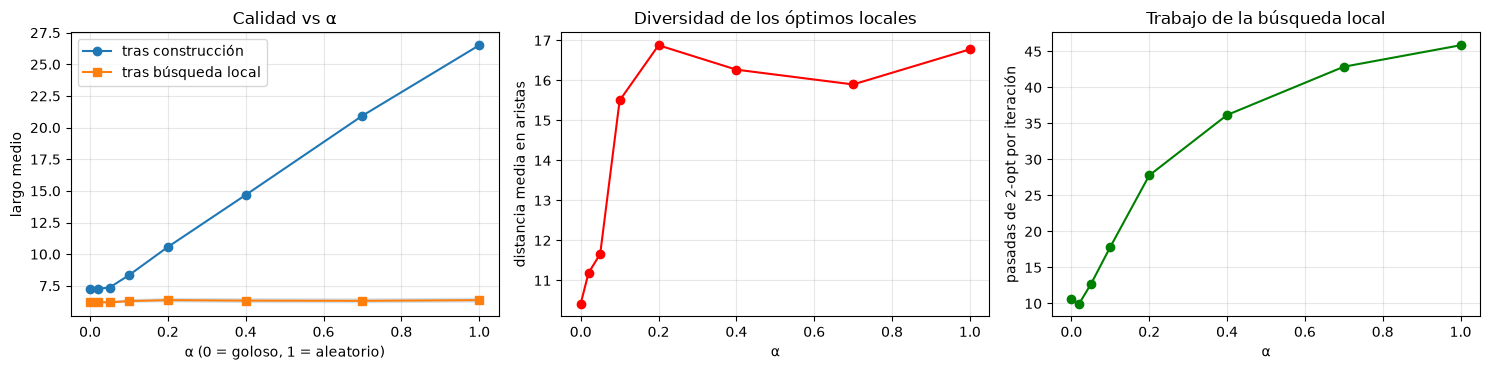

In [5]:
f = np.array(filas_a)
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
ax[0].plot(f[:, 0], f[:, 1], "o-", label="tras construcción"); ax[0].plot(f[:, 0], f[:, 2], "s-", label="tras búsqueda local")
ax[0].fill_between(f[:, 0], f[:, 2] - f[:, 3], f[:, 2] + f[:, 3], alpha=0.2)
ax[0].set_xlabel("α (0 = goloso, 1 = aleatorio)"); ax[0].set_ylabel("largo medio"); ax[0].set_title("Calidad vs α"); ax[0].legend()
ax[1].plot(f[:, 0], f[:, 6], "o-r"); ax[1].set_xlabel("α"); ax[1].set_ylabel("distancia media en aristas")
ax[1].set_title("Diversidad de los óptimos locales")
ax[2].plot(f[:, 0], f[:, 5], "o-g"); ax[2].set_xlabel("α"); ax[2].set_ylabel("pasadas de 2-opt por iteración")
ax[2].set_title("Trabajo de la búsqueda local")
plt.tight_layout(); plt.show()

**Lectura.** Mira las columnas de la tabla: la calidad **tras la construcción** empeora al subir $\alpha$ (más aleatoriedad), el
trabajo de la búsqueda local crece (parte de peor punto) y la diversidad de los óptimos locales aumenta. La calidad **tras la
búsqueda local** no es monótona de la misma manera: la búsqueda local compensa gran parte de la diferencia de construcción.
Lo que importa para GRASP no es la media de una iteración, sino **el mejor de $N$**, que premia la diversidad.
Lo medimos directamente con un presupuesto fijo de trabajo y varias semillas. Nota: con $\alpha=0$ la única aleatoriedad es la ciudad inicial, por lo que solo hay $n$ construcciones distintas y la desviación entre semillas tiende a cero (se agotan las construcciones).

[11.1s]  GRASP con 2000 evaluaciones de vecindario, 8 semillas
    α |   mejor final (media ± sd) |     mín
  0.0 |            6.0778 ± 0.0000 |  6.0778
 0.02 |            6.0483 ± 0.0026 |  6.0474
 0.05 |            6.0511 ± 0.0057 |  6.0474
  0.1 |            6.0561 ± 0.0073 |  6.0474
  0.2 |            6.0661 ± 0.0131 |  6.0474
  0.4 |            6.0734 ± 0.0173 |  6.0474
  0.7 |            6.0636 ± 0.0108 |  6.0474
  1.0 |            6.0744 ± 0.0296 |  6.0474


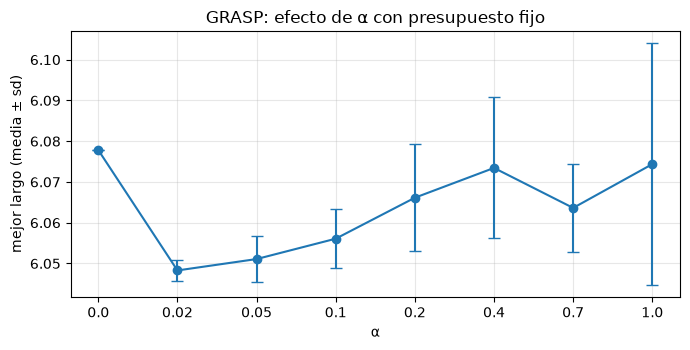

In [6]:
def grasp_simple(D, presupuesto, rng, alpha=None, k=None):
    # GRASP básico con presupuesto en evaluaciones de vecindario. Devuelve mejor largo.
    I, J = pares_2opt(len(D)); trabajo = [0]; mejor = np.inf
    while trabajo[0] < presupuesto:
        t = construir(D, rng, alpha=alpha, k=k); trabajo[0] += 1
        t, L = ls_2opt(D, t, I, J, trabajo)
        mejor = min(mejor, L)
    return mejor

PRESUP = 2000; SEMILLAS = list(range(8))
def resumen(x):
    x = np.asarray(x); return f"{x.mean():.4f} ± {x.std(ddof=1):.4f}"

t0 = time.time()
res_alpha = {a: [grasp_simple(D, PRESUP, np.random.default_rng(100 + s), alpha=a) for s in SEMILLAS] for a in ALFAS}
print(f"[{time.time()-t0:.1f}s]  GRASP con {PRESUP} evaluaciones de vecindario, 8 semillas")
print(f"{'α':>5} | {'mejor final (media ± sd)':>26} | {'mín':>7}")
for a in ALFAS:
    print(f"{a:>5} | {resumen(res_alpha[a]):>26} | {min(res_alpha[a]):>7.4f}")

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.errorbar(range(len(ALFAS)), [np.mean(res_alpha[a]) for a in ALFAS], yerr=[np.std(res_alpha[a], ddof=1) for a in ALFAS], fmt="o-", capsize=4)
ax.set_xticks(range(len(ALFAS))); ax.set_xticklabels(ALFAS); ax.set_xlabel("α"); ax.set_ylabel("mejor largo (media ± sd)")
ax.set_title("GRASP: efecto de α con presupuesto fijo"); plt.tight_layout(); plt.show()

### RCL por cardinalidad
Con $k$ fijo, la RCL siempre tiene $k$ candidatos, sin importar cuán dispersos estén los costos. En el TSP, cuando quedan pocas
ciudades sin visitar la RCL por cardinalidad se vuelve más permisiva que una RCL por valor, y por eso son parametrizaciones distintas.

In [7]:
KS = [1, 2, 3, 5, 8, 12]
t0 = time.time()
filas_k = barrido_rcl(KS, "k")
res_k = {k: [grasp_simple(D, PRESUP, np.random.default_rng(100 + s), k=k) for s in SEMILLAS] for k in KS}
print(f"[{time.time()-t0:.1f}s]")
print(f"{'k':>3} | {'construcción':>12} | {'tras LS':>8} | {'diversidad':>10} | {'GRASP final (media ± sd)':>26}")
for (k, lc, ll, sl, mn, ps, dv) in filas_k:
    print(f"{k:>3} | {lc:>12.3f} | {ll:>8.3f} | {dv:>10.1f} | {resumen(res_k[k]):>26}")

[8.4s]
  k | construcción |  tras LS | diversidad |   GRASP final (media ± sd)
  1 |        7.268 |    6.237 |       10.4 |            6.0778 ± 0.0000
  2 |        9.807 |    6.337 |       16.3 |            6.0530 ± 0.0106
  3 |       11.553 |    6.360 |       17.2 |            6.0689 ± 0.0183
  5 |       14.306 |    6.293 |       15.5 |            6.0756 ± 0.0162
  8 |       17.165 |    6.365 |       16.8 |            6.0776 ± 0.0271
 12 |       20.094 |    6.365 |       17.1 |            6.0827 ± 0.0278


## 6. GRASP reactivo

Prais & Ribeiro (2000) proponen **no fijar** $\alpha$: se mantiene un conjunto $\Psi=\{\alpha_1,\dots,\alpha_m\}$ con probabilidades
$p_i$ (inicialmente uniformes). Cada $N_\alpha$ iteraciones se reevalúan según el desempeño de cada valor:

$$
q_i=\Big(\frac{F^{*}}{A_i}\Big)^{\delta},\qquad p_i=\frac{q_i}{\sum_{j}q_j},
$$

donde $F^{*}$ es el mejor costo hallado y $A_i$ el costo medio de las soluciones obtenidas con $\alpha_i$ (para minimización
$A_i\ge F^{*}$, así que $q_i\le1$ y es mayor para los valores que producen mejores soluciones). El exponente $\delta$ controla qué tan
agresivamente se favorece a los mejores valores. Es un ejemplo de **memoria de aprendizaje sobre parámetros**.

## 7. GRASP con memoria

Fleurent & Glover (1999) proponen usar **memoria adaptativa** en la construcción: las aristas que aparecen con frecuencia en
las soluciones élite reciben un bono. Aquí, con el pool de élite $\mathcal{E}$ y $\phi_{uv}$ la fracción de élites que contienen la
arista $(u,v)$, el costo del candidato es

$$
c'(v)=d(u,v)-\gamma\,\bar d\,\phi_{uv},
$$

donde $\gamma\ge0$ es el peso de la memoria y $\bar d$ la distancia media (escala). Con $\gamma=0$ se recupera GRASP básico.
La construcción tiende hacia regiones prometedoras (intensificación) y la RCL mantiene la variabilidad.

Para ello necesitamos primero el **pool de élite** (sección 10) y los operadores de Path Relinking (sección 9). Los definimos
a continuación y luego los ensamblamos en un solo motor GRASP con todas las opciones.

## 8. Distancias entre permutaciones

A partir de aquí usamos una instancia **más grande** ($n=100$), donde las diferencias entre variantes son más visibles
(en $n=50$ el 2-opt con reinicios ya encuentra casi siempre el mismo mejor tour).

Un tour es una permutación **cíclica y sin orientación**: rotar el tour o recorrerlo en sentido inverso no cambia la solución.
Tres distancias comunes:

| Distancia | Definición | Qué mide | Invariante a rotación/sentido |
|---|---|---|---|
| **Hamming (posiciones)** | $\min_{\text{alineación}}\ \#\{i: s_i\ne s'_i\}$ | posiciones con distinta ciudad | solo tras minimizar sobre alineaciones |
| **Aristas** | $n-\lvert E(s)\cap E(s')\rvert$ | aristas que difieren | sí, por definición |
| **Kendall-tau** | $\min_{\text{alineación}}\ \#\{(i,j): \text{pares en orden inverso}\}$ (simetrizada con el mínimo de ambas direcciones) | nº mínimo de transposiciones adyacentes | solo tras minimizar sobre alineaciones |

La distancia de **aristas** es la natural para el TSP: la calidad de un tour depende de las aristas que contiene. Hamming y
Kendall-tau son naturales en asignación (QAP), donde la posición importa. Verificamos propiedades (identidad, simetría,
invariancia) y comparamos las tres.

In [8]:
P100, D100 = crear_tsp(100, np.random.default_rng(8))
I100, J100 = pares_2opt(100)

def variantes(t):
    # Todas las rotaciones del tour y de su reflejo: 2n variantes de la misma solución.
    n = len(t); idx = (np.arange(n)[None, :] + np.arange(n)[:, None]) % n
    return np.vstack([t[idx], t[::-1][idx]])

def alinear_a(t, ref):
    # Variante de t con menor distancia de Hamming a ref.
    V = variantes(t); h = (V != ref[None, :]).sum(1)
    return V[int(np.argmin(h))]

def dist_hamming(t1, t2):
    V = variantes(t2); return int((V != t1[None, :]).sum(1).min())

def _kendall_dir(t1, t2):
    # Mínimo sobre alineaciones de t2 del nº de inversiones (pares discordantes) respecto a t1.
    n = len(t1); mejor = np.inf
    triu = np.triu(np.ones((n, n), bool), 1)
    for v in variantes(t2):
        pos = np.empty(n, int); pos[v] = np.arange(n)
        sec = pos[t1]
        inv = int(((sec[:, None] > sec[None, :]) & triu).sum())
        mejor = min(mejor, inv)
    return mejor

def dist_kendall(t1, t2):
    # Se simetriza tomando el mínimo de ambas direcciones de alineación.
    return min(_kendall_dir(t1, t2), _kendall_dir(t2, t1))

# Propiedades
rng = np.random.default_rng(5)
a, b, c = (rng.permutation(50) for _ in range(3))
r = np.roll(a, 7)[::-1]                       # misma solución rotada y reflejada
print("d(a,a)=0 :", dist_aristas(a, a), dist_hamming(a, a), dist_kendall(a, a))
print("d(a,rot/refl(a))=0 :", dist_aristas(a, r), dist_hamming(a, r), dist_kendall(a, r))
print("simetría aristas :", dist_aristas(a, b) == dist_aristas(b, a), "| Hamming:", dist_hamming(a, b) == dist_hamming(b, a),
      "| Kendall:", dist_kendall(a, b) == dist_kendall(b, a))
print("desigualdad triangular (aristas):", dist_aristas(a, c) <= dist_aristas(a, b) + dist_aristas(b, c))
# Un 2-opt cambia exactamente 2 aristas pero puede cambiar muchas posiciones:
t_ = rng.permutation(50); u_ = aplicar_2opt(t_, 5, 40)
print(f"Un 2-opt sobre un segmento de 35 ciudades: dist. aristas={dist_aristas(t_, u_)}, Hamming={dist_hamming(t_, u_)}, Kendall={dist_kendall(t_, u_)}")

d(a,a)=0 : 0 0 0
d(a,rot/refl(a))=0 : 0 0 0
simetría aristas : True | Hamming: True | Kendall: True
desigualdad triangular (aristas): True
Un 2-opt sobre un segmento de 35 ciudades: dist. aristas=2, Hamming=14, Kendall=261


El último ejemplo ilustra la diferencia clave: un movimiento 2-opt cambia solo **2 aristas** (distancia de aristas $=2$)
pero revierte un segmento largo, así que Hamming y Kendall-tau lo ven como un cambio enorme. Para TSP, la distancia de aristas es
la que refleja el tamaño del movimiento; aun así miramos si las tres miden lo mismo sobre óptimos locales reales.

### Estructura del paisaje: óptimos locales, distancia y calidad

Generamos 150 óptimos locales (GRASP con $\alpha=0.3$) y estudiamos (a) la correlación entre las tres distancias sobre pares
de óptimos y (b) si los mejores óptimos locales están **cerca entre sí** (hipótesis del "valle grande", *big valley*), lo que
justifica el Path Relinking: si las buenas soluciones se agrupan, el camino entre dos de ellas pasa por una región prometedora.

Spearman aristas~Hamming : 0.669
Spearman aristas~Kendall : 0.388
Spearman Hamming~Kendall : 0.441
Correlación (Spearman) entre largo del óptimo local y su distancia (aristas) al mejor: 0.698 (p=4.3e-23)


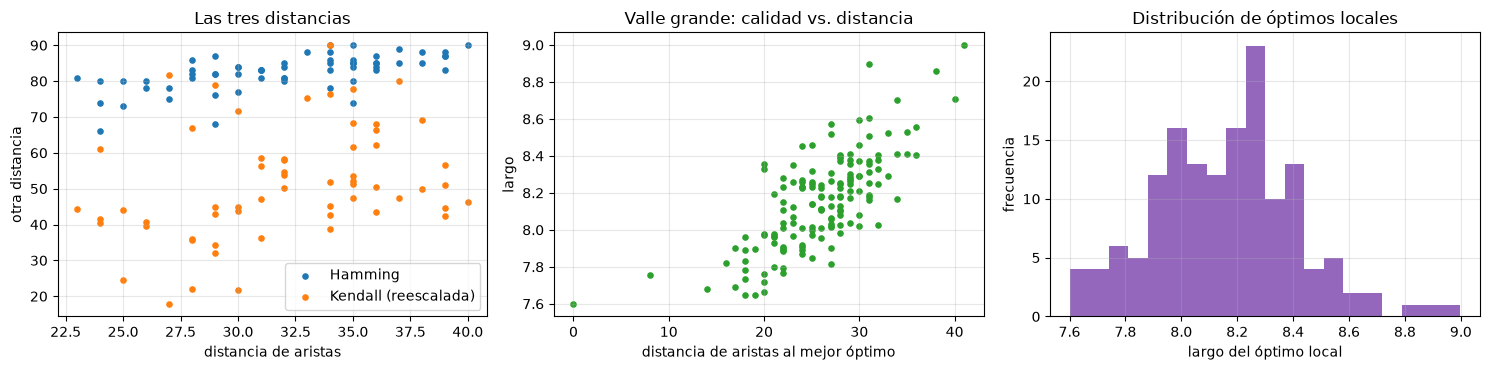

In [9]:
rng = np.random.default_rng(11)
opt = []
for _ in range(150):
    t, L = ls_2opt(D100, construir(D100, rng, alpha=0.3), I100, J100); opt.append((L, t))
Ls_opt = np.array([o[0] for o in opt])
# mejor tour de referencia: el mejor de los óptimos más un ILS corto desde él (solo como referencia para el gráfico)
mejor_ref = opt[int(np.argmin(Ls_opt))][1]
d_ref = np.array([dist_aristas(o[1], mejor_ref) for o in opt])

pares = [tuple(rng.choice(150, 2, replace=False)) for _ in range(60)]
dh = [dist_hamming(opt[i][1], opt[j][1]) for i, j in pares]
de = [dist_aristas(opt[i][1], opt[j][1]) for i, j in pares]
dk = [dist_kendall(opt[i][1], opt[j][1]) for i, j in pares]
print("Spearman aristas~Hamming :", f"{spearmanr(de, dh)[0]:.3f}")
print("Spearman aristas~Kendall :", f"{spearmanr(de, dk)[0]:.3f}")
print("Spearman Hamming~Kendall :", f"{spearmanr(dh, dk)[0]:.3f}")
rho, pval = spearmanr(d_ref[d_ref > 0], Ls_opt[d_ref > 0])
print(f"Correlación (Spearman) entre largo del óptimo local y su distancia (aristas) al mejor: {rho:.3f} (p={pval:.2g})")

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
ax[0].scatter(de, dh, s=14, label="Hamming"); ax[0].scatter(de, np.array(dk) / max(dk) * max(dh), s=14, label="Kendall (reescalada)")
ax[0].set_xlabel("distancia de aristas"); ax[0].set_ylabel("otra distancia"); ax[0].set_title("Las tres distancias"); ax[0].legend()
ax[1].scatter(d_ref, Ls_opt, s=14, c="C2"); ax[1].set_xlabel("distancia de aristas al mejor óptimo"); ax[1].set_ylabel("largo")
ax[1].set_title("Valle grande: calidad vs. distancia")
ax[2].hist(Ls_opt, bins=20, color="C4"); ax[2].set_xlabel("largo del óptimo local"); ax[2].set_ylabel("frecuencia"); ax[2].set_title("Distribución de óptimos locales")
plt.tight_layout(); plt.show()

## 9. Path Relinking

**Path Relinking** (Glover, 1997; Glover, Laguna & Martí, 2000; Resende & Ribeiro) explora la **trayectoria** que conecta dos
soluciones de calidad, la *inicial* $s$ y la *guía* $g$: partiendo de $s$, se aplican movimientos que **reducen la distancia** a
$g$ hasta alcanzarla. Se evalúan las soluciones intermedias y se conserva la mejor (que suele refinarse con búsqueda local).

```
PATH_RELINKING(s, g):
    cur ← s;  mejor_interm ← ∅
    mientras dist(cur, g) > 1:
        elegir el mejor movimiento m (según f) entre los que reducen dist(·, g)
        cur ← cur ⊕ m
        si cur está en la zona interior del camino y f(cur) < f(mejor_interm): mejor_interm ← cur
    devolver mejor_interm
```

Variantes:
- **Forward**: $s$ = solución nueva (de GRASP), $g$ = élite. Se camina de la nueva hacia la élite.
- **Backward**: se intercambian los roles: se parte de la élite hacia la nueva (explora un entorno de la élite; usualmente
  más fuerte porque parte de una solución mejor).
- **Mixto**: se avanza alternando pasos de $s$ hacia $g$ y de $g$ hacia $s$ hasta que se encuentran.

**Dos tipos de movimiento** (ambos verificados abajo):
1. *Por aristas (2-opt):* se aplica el 2-opt que **agrega aristas de $g$** ausentes en la solución actual, eligiendo el de menor
   costo entre los que aumentan estrictamente el número de aristas comunes (distancia de aristas disminuye).
2. *Por posiciones (intercambios, Hamming):* se alinea $g$ a la solución actual y se intercambian dos ciudades de modo que una
   posición más coincida con $g$ (la distancia de Hamming baja al menos en 1: garantiza terminación).

In [10]:
def adyac_pesos(tours, n):
    # Fracción de tours del conjunto que contiene cada arista (matriz n×n simétrica).
    G = np.zeros((n, n))
    for t in tours:
        G += adyacencia(t)
    return G / max(1, len(tours))

def paso_aristas(D, cur, objetivo, I, J):
    # Un 2-opt que aumenta estrictamente las aristas comunes con 'objetivo'; el de menor costo. None si no hay.
    G = adyacencia(objetivo)
    a = cur; b = np.roll(cur, -1)
    ai, aj, bi, bj = a[I], a[J], b[I], b[J]
    ganancia = G[ai, aj].astype(int) + G[bi, bj] - G[ai, bi] - G[aj, bj]
    dl = D[ai, aj] + D[bi, bj] - D[ai, bi] - D[aj, bj]
    ok = ganancia > 0
    if not ok.any():
        return None
    k = int(np.argmin(np.where(ok, dl, np.inf)))
    return aplicar_2opt(cur, I[k], J[k])

def paso_hamming(D, cur, objetivo, I=None, J=None):
    # Un intercambio de dos posiciones que corrige al menos una posición respecto al objetivo alineado.
    n = len(cur); g = alinear_a(objetivo, cur)
    mism = np.flatnonzero(cur != g)
    if len(mism) <= 1:
        return None
    pos = np.empty(n, int); pos[cur] = np.arange(n)
    C = np.tile(cur, (len(mism), 1))
    j = pos[g[mism]]
    C[np.arange(len(mism)), mism] = g[mism]
    C[np.arange(len(mism)), j] = cur[mism]
    L = D[C, np.roll(C, 1, axis=1)].sum(1)
    return C[int(np.argmin(L))]

PASOS = {"aristas": paso_aristas, "hamming": paso_hamming}

def path_relinking(D, s, g, I, J, modo="aristas", direccion="adelante", trabajo=None, max_frac=(0.2, 0.2)):
    # Devuelve (mejor tour intermedio o None, info del camino).
    # direccion: 'adelante' (s->g), 'atras' (g->s) o 'mixto' (alternando desde ambos extremos).
    paso = PASOS[modo]
    d0 = dist_aristas(s, g)
    if d0 < 4:
        return None, dict(largos=[], dist=[], truncado=False)
    a, b = (s, g) if direccion != "atras" else (g, s)
    mejor, Lmej = None, np.inf; largos, dists = [], []; trunc = False
    zona = max(2, int(0.2 * d0))
    turno = 0
    while dist_aristas(a, b) > 1:
        if direccion == "mixto" and turno % 2 == 1:
            nuevo = paso(D, b, a, I, J)
            if nuevo is None: trunc = True; break
            b = nuevo; actual = b
        else:
            nuevo = paso(D, a, b, I, J)
            if nuevo is None: trunc = True; break
            a = nuevo; actual = a
        turno += 1
        if trabajo is not None: trabajo[0] += 1
        L = largo_tour(D, actual); da, db = dist_aristas(actual, s), dist_aristas(actual, g)
        largos.append(L); dists.append(dist_aristas(actual, g))
        if min(da, db) >= zona and L < Lmej:
            mejor, Lmej = actual.copy(), L
    return mejor, dict(largos=largos, dist=dists, truncado=trunc, d0=d0)

# Verificación: el camino reduce la distancia de forma monótona y los tours intermedios son válidos.
# Par de óptimos locales (de los 150 generados arriba) con distancia de aristas máxima entre 40 pares aleatorios
rng = np.random.default_rng(1)
cand_p = [tuple(rng.choice(150, 2, replace=False)) for _ in range(40)]
ip, jp = max(cand_p, key=lambda p_: dist_aristas(opt[p_[0]][1], opt[p_[1]][1]))
s0, g0 = opt[ip][1], opt[jp][1]
print(f"Par elegido: distancia de aristas {dist_aristas(s0, g0)}, Hamming {dist_hamming(s0, g0)}")
for modo in ("aristas", "hamming"):
    cur = s0.copy(); dd = [dist_aristas(cur, g0)] if modo == "aristas" else [dist_hamming(cur, g0)]
    while True:
        nuevo = PASOS[modo](D100, cur, g0, I100, J100)
        if nuevo is None: break
        assert es_permutacion(nuevo, 100)
        cur = nuevo; dd.append(dist_aristas(cur, g0) if modo == "aristas" else dist_hamming(cur, g0))
    mono = all(x > y for x, y in zip(dd[:-1], dd[1:]))
    print(f"{modo:>8}: distancia inicial {dd[0]}, final {dd[-1]}, pasos {len(dd)-1}, estrictamente decreciente: {mono}")

Par elegido: distancia de aristas 39, Hamming 72
 aristas: distancia inicial 39, final 3, pasos 33, estrictamente decreciente: True
 hamming: distancia inicial 72, final 0, pasos 65, estrictamente decreciente: True


Visualizamos el camino entre dos óptimos locales: costo de las soluciones intermedias y distancia restante a la guía, para
las tres direcciones y ambos movimientos. El mejor intermedio se refina con 2-opt.

Extremos: s (inicial) = 8.411, g (guía) = 8.210, distancia de aristas = 39
   aristas/adelante: pasos= 33, truncado=True, mejor intermedio=8.068 → tras LS=7.903
   aristas/atras   : pasos= 34, truncado=True, mejor intermedio=8.127 → tras LS=8.119
   aristas/mixto   : pasos= 35, truncado=False, mejor intermedio=8.242 → tras LS=7.945
   hamming/adelante: pasos= 65, truncado=False, mejor intermedio=8.486 → tras LS=8.411
   hamming/atras   : pasos= 65, truncado=False, mejor intermedio=8.361 → tras LS=8.210


   hamming/mixto   : pasos= 65, truncado=False, mejor intermedio=8.402 → tras LS=8.210


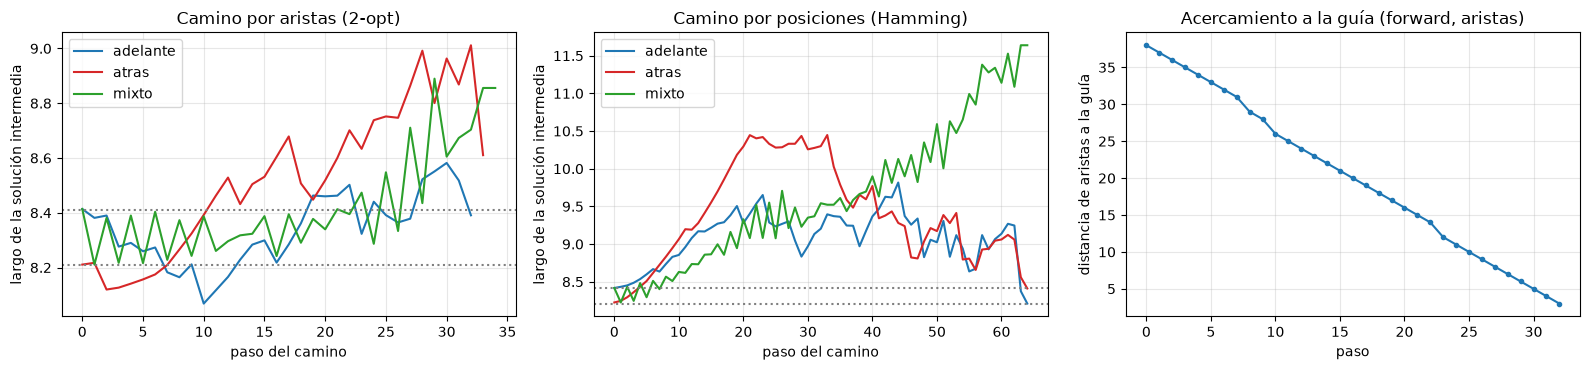

In [11]:
fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
colores = {"adelante": "C0", "atras": "C3", "mixto": "C2"}
Lbase = (largo_tour(D100, s0), largo_tour(D100, g0))
print(f"Extremos: s (inicial) = {Lbase[0]:.3f}, g (guía) = {Lbase[1]:.3f}, distancia de aristas = {dist_aristas(s0, g0)}")
for modo, fila in (("aristas", 0), ("hamming", 1)):
    for dirc, col in colores.items():
        tr = [0]
        mej, info = path_relinking(D100, s0, g0, I100, J100, modo=modo, direccion=dirc, trabajo=tr)
        if modo == "aristas":
            ax[0].plot(info["largos"], color=col, label=f"{dirc}")
        else:
            ax[1].plot(info["largos"], color=col, label=f"{dirc}")
        if mej is not None:
            t2, L2 = ls_2opt(D100, mej, I100, J100)
            print(f"  {modo:>8}/{dirc:<8}: pasos={len(info['largos']):>3}, truncado={info['truncado']}, "
                  f"mejor intermedio={largo_tour(D100, mej):.3f} → tras LS={L2:.3f}")
ax[0].set_title("Camino por aristas (2-opt)"); ax[1].set_title("Camino por posiciones (Hamming)")
for a_ in ax[:2]:
    a_.set_xlabel("paso del camino"); a_.set_ylabel("largo de la solución intermedia"); a_.legend()
    a_.axhline(Lbase[0], color="gray", ls=":"); a_.axhline(Lbase[1], color="gray", ls=":")
mej, info = path_relinking(D100, s0, g0, I100, J100, modo="aristas", direccion="adelante")
ax[2].plot(info["dist"], "o-", ms=3); ax[2].set_xlabel("paso"); ax[2].set_ylabel("distancia de aristas a la guía"); ax[2].set_title("Acercamiento a la guía (forward, aristas)")
plt.tight_layout(); plt.show()

In [12]:
# Diagnóstico sobre 30 pares de óptimos locales: ¿qué fracción del camino recorre cada tipo de movimiento?
rng = np.random.default_rng(2)
pares_d = [tuple(rng.choice(150, 2, replace=False)) for _ in range(30)]
print(f"{'movimiento':>10} | {'dirección':>9} | {'pasos / d0':>10} | {'caminos truncados':>17} | {'largo interm. mín / mejor extremo':>33}")
for modo in ("aristas", "hamming"):
    for dirc in ("adelante", "atras", "mixto"):
        fr, tr_, rat = [], 0, []
        for (i, j) in pares_d:
            s_, g_ = opt[i][1], opt[j][1]
            m_, inf_ = path_relinking(D100, s_, g_, I100, J100, modo=modo, direccion=dirc)
            if "d0" not in inf_: continue
            fr.append(len(inf_["largos"]) / inf_["d0"]); tr_ += inf_["truncado"]
            if inf_["largos"]: rat.append(min(inf_["largos"]) / min(opt[i][0], opt[j][0]))
        print(f"{modo:>10} | {dirc:>9} | {np.mean(fr):>10.2f} | {tr_:>7}/{len(fr):<9} | {np.mean(rat):>33.3f}")

movimiento | dirección | pasos / d0 | caminos truncados | largo interm. mín / mejor extremo


   aristas |  adelante |       0.84 |      11/30        |                             0.992


   aristas |     atras |       0.83 |      11/30        |                             0.990


   aristas |     mixto |       0.83 |      14/30        |                             0.988


   hamming |  adelante |       2.47 |       0/30        |                             1.001


   hamming |     atras |       2.47 |       0/30        |                             1.002


   hamming |     mixto |       2.47 |       0/30        |                             1.006


**Observaciones (verificadas con las salidas de arriba).**
- Los tours intermedios del camino por **aristas** suben de costo a mitad de camino (se pasa por "valles" entre los dos óptimos),
  pero a lo sumo unos pocos puntos porcentuales por encima de los extremos, y **a veces hay intermedios mejores que ambos extremos**
  (el mínimo del camino respecto al mejor extremo está en la última columna del diagnóstico: valores $<1$ indican que el camino
  contiene soluciones mejores que el mejor extremo).
- Los caminos por **posiciones (Hamming)** pasan por tours bastante peores (el eje vertical llega mucho más arriba): los intercambios
  de posiciones **rompen aristas** buenas porque no respetan la estructura del TSP. Sus pasos son además más numerosos
  (cada paso corrige una posición, no una arista; por eso "pasos / d0" supera 1: $d_0$ está medida en aristas).
- El camino por aristas **se trunca** en una fracción apreciable de los pares (columna "caminos truncados"): cuando ningún 2-opt
  aumenta estrictamente las aristas comunes, las diferencias restantes requieren movimientos más ricos (Or-opt, 3-opt). Es una
  limitación honesta de esta elección de movimiento; el mejor intermedio se calcula con lo recorrido.

Es la consecuencia directa de la sección 8: el movimiento debe estar alineado con la **estructura** del problema. El experimento
final cuantifica qué variante rinde mejor en el GRASP+PR completo.

## 10. Pool de élite y GRASP + Path Relinking

El **pool élite** guarda hasta $\text{cap}$ soluciones buenas **y diversas**. Regla de admisión:
1. si ya hay una solución idéntica (distancia 0), se rechaza;
2. si hay espacio, se agrega;
3. si está lleno, solo entra si mejora a la peor; reemplaza a la **más parecida** (distancia de aristas mínima) entre las que son peores que ella.

La solución guía de cada Path Relinking se sortea del pool **con probabilidad proporcional a su distancia** a la solución nueva
(favorece guías diferentes, donde hay más camino por explorar). El motor siguiente implementa GRASP básico, reactivo, con memoria
y con Path Relinking (cualquier dirección y movimiento) bajo el mismo presupuesto de evaluaciones.

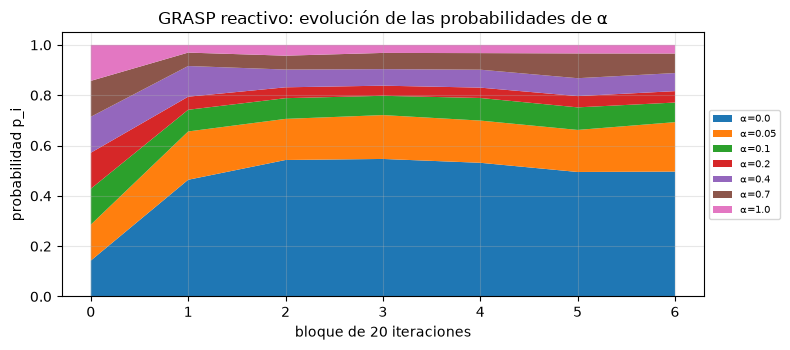

Probabilidades finales: {0.0: 0.496, 0.05: 0.197, 0.1: 0.078, 0.2: 0.045, 0.4: 0.072, 0.7: 0.078, 1.0: 0.034}


In [13]:
def pool_insertar(pool, L, t, cap):
    # pool: lista de (largo, tour). Devuelve True si se insertó.
    if any(dist_aristas(t, e[1]) == 0 for e in pool):
        return False
    if len(pool) < cap:
        pool.append((L, t.copy())); return True
    peor = max(e[0] for e in pool)
    if L >= peor - 1e-12:
        return False
    peores = [i for i, e in enumerate(pool) if e[0] >= L]
    i_rep = min(peores, key=lambda i: dist_aristas(t, pool[i][1]))
    pool[i_rep] = (L, t.copy()); return True

def grasp(D, presupuesto, rng, alpha=0.1, alphas=None, delta_r=30, bloque=20, memoria=0.0,
          pr=None, modo="aristas", cap=8, registrar=False):
    # Motor GRASP. pr: None, 'adelante', 'atras' o 'mixto'. alphas: lista para GRASP reactivo.
    n = len(D); I, J = pares_2opt(n); trabajo = [0]
    pool = []; mejor, t_mejor = np.inf, None; hist = []; escala = D.mean()
    if alphas is not None:
        AL = np.array(alphas); prob = np.ones(len(AL)) / len(AL)
        suma = np.zeros(len(AL)); cuenta = np.zeros(len(AL)); hist_prob = [prob.copy()]
    it = 0
    while trabajo[0] < presupuesto:
        it += 1
        if alphas is not None:
            ia = int(rng.choice(len(AL), p=prob)); a = AL[ia]
        else:
            a = alpha
        bono = None
        if memoria > 0 and len(pool) >= 3:
            bono = memoria * escala * adyac_pesos([e[1] for e in pool], n)
        t = construir(D, rng, alpha=a, bono=bono); trabajo[0] += 1
        t, L = ls_2opt(D, t, I, J, trabajo)
        if alphas is not None:
            suma[ia] += L; cuenta[ia] += 1
            if it % bloque == 0:
                medias = np.where(cuenta > 0, suma / np.maximum(cuenta, 1), suma.sum() / max(1, cuenta.sum()))
                q = (mejor / medias) ** delta_r; prob = q / q.sum(); hist_prob.append(prob.copy())
        if L < mejor - 1e-12:
            mejor, t_mejor = L, t.copy()
        if pr is not None and len(pool) >= 2:
            d = np.array([dist_aristas(t, e[1]) for e in pool], float)
            if d.sum() > 0:
                g = pool[int(rng.choice(len(pool), p=d / d.sum()))][1]
                interm, _ = path_relinking(D, t, g, I, J, modo=modo, direccion=pr, trabajo=trabajo)
                if interm is not None:
                    t2, L2 = ls_2opt(D, interm, I, J, trabajo)
                    if L2 < mejor - 1e-12:
                        mejor, t_mejor = L2, t2.copy()
                    pool_insertar(pool, L2, t2, cap)
        if pr is not None or memoria > 0:
            pool_insertar(pool, L, t, cap)
        if registrar:
            hist.append((trabajo[0], mejor))
    assert es_permutacion(t_mejor, n) and abs(largo_tour(D, t_mejor) - mejor) < 1e-8
    out = dict(mejor=mejor, tour=t_mejor, iters=it, hist=hist)
    if alphas is not None:
        out["prob"] = np.array(hist_prob); out["alphas"] = AL
    return out

# Reactivo: efecto sobre las probabilidades
ALFAS_R = [0.0, 0.05, 0.1, 0.2, 0.4, 0.7, 1.0]
rr = grasp(D100, 6000, np.random.default_rng(0), alphas=ALFAS_R, bloque=20, delta_r=30)
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.stackplot(range(len(rr["prob"])), rr["prob"].T, labels=[f"α={a}" for a in ALFAS_R])
ax.set_xlabel("bloque de 20 iteraciones"); ax.set_ylabel("probabilidad p_i"); ax.set_title("GRASP reactivo: evolución de las probabilidades de α")
ax.legend(fontsize=7, loc="center left", bbox_to_anchor=(1, 0.5)); plt.tight_layout(); plt.show()
print("Probabilidades finales:", {a: round(float(p), 3) for a, p in zip(ALFAS_R, rr["prob"][-1])})

## 11. Comparación empírica

Variantes con el **mismo presupuesto** de evaluaciones de vecindario (5000 por corrida), 8 semillas por variante (las mismas
semillas para todas) sobre la misma instancia. Cada corrida es independiente. Reportamos media $\pm$ desviación estándar del mejor
largo y la brecha respecto al **mejor tour observado en todo el notebook** (no es necesariamente el óptimo).

In [14]:
PRESUP2 = 5000
VARIANTES = {
    "GRASP α=0.1":                dict(alpha=0.1),
    "GRASP α=0.3":                dict(alpha=0.3),
    "GRASP reactivo":             dict(alphas=ALFAS_R),
    "GRASP + memoria (γ=1)":      dict(alpha=0.1, memoria=1.0),
    "GRASP+PR adelante (aristas)":dict(alpha=0.1, pr="adelante", modo="aristas"),
    "GRASP+PR atrás (aristas)":   dict(alpha=0.1, pr="atras", modo="aristas"),
    "GRASP+PR mixto (aristas)":   dict(alpha=0.1, pr="mixto", modo="aristas"),
    "GRASP+PR adelante (Hamming)":dict(alpha=0.1, pr="adelante", modo="hamming"),
}
SEM = list(range(8))
t0 = time.time(); resultados = {}
for nombre, kw in VARIANTES.items():
    tt = time.time()
    rs = [grasp(D100, PRESUP2, np.random.default_rng(500 + s), registrar=True, **kw) for s in SEM]
    resultados[nombre] = (rs, time.time() - tt)
print(f"[{time.time()-t0:.1f}s total]")
mejor_global = min(min(r["mejor"] for r in rs) for rs, _ in resultados.values())
mejor_global = min(mejor_global, Ls_opt.min())
print(f"Mejor tour observado: {mejor_global:.4f}")
print(f"{'variante':<30} | {'mejor (media ± sd)':>20} | {'mín':>7} | {'brecha media':>12} | {'iter. GRASP':>11} | {'seg/corrida':>11}")
for nombre, (rs, tm) in resultados.items():
    m = np.array([r["mejor"] for r in rs])
    print(f"{nombre:<30} | {resumen(m):>20} | {m.min():>7.4f} | {100*(m.mean()/mejor_global-1):>11.2f}% | "
          f"{np.mean([r['iters'] for r in rs]):>11.1f} | {tm/len(SEM):>11.2f}")

[85.0s total]
Mejor tour observado: 7.4670
variante                       |   mejor (media ± sd) |     mín | brecha media | iter. GRASP | seg/corrida
GRASP α=0.1                    |      7.6283 ± 0.0801 |  7.5049 |        2.16% |       104.4 |        0.83
GRASP α=0.3                    |      7.6860 ± 0.0509 |  7.6105 |        2.93% |        62.1 |        0.72
GRASP reactivo                 |      7.5220 ± 0.0069 |  7.5069 |        0.74% |       104.5 |        0.73
GRASP + memoria (γ=1)          |      7.5227 ± 0.0770 |  7.4670 |        0.75% |       938.8 |        2.12
GRASP+PR adelante (aristas)    |      7.4981 ± 0.0333 |  7.4675 |        0.42% |        66.9 |        2.26
GRASP+PR atrás (aristas)       |      7.4867 ± 0.0276 |  7.4670 |        0.26% |        67.4 |        1.65
GRASP+PR mixto (aristas)       |      7.4903 ± 0.0156 |  7.4675 |        0.31% |        67.6 |        1.14
GRASP+PR adelante (Hamming)    |      7.6375 ± 0.0958 |  7.5273 |        2.28% |        41.1 |       

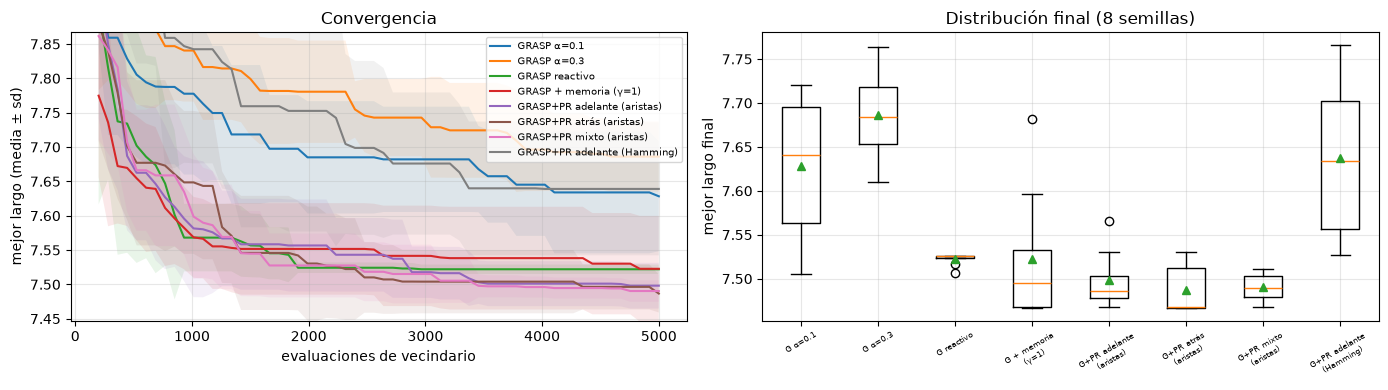

In [15]:
# Curvas de convergencia (mejor-hasta-ahora vs trabajo) con media ± sd sobre las semillas
malla = np.linspace(200, PRESUP2, 60)
def curva(rs):
    M = []
    for r in rs:
        h = np.array(r["hist"]); idx = np.searchsorted(h[:, 0], malla, side="right") - 1
        M.append(np.where(idx >= 0, h[np.maximum(idx, 0), 1], np.nan))
    return np.nanmean(M, 0), np.nanstd(M, 0, ddof=1)

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for nombre, (rs, _) in resultados.items():
    m, s = curva(rs)
    ax[0].plot(malla, m, label=nombre); ax[0].fill_between(malla, m - s, m + s, alpha=0.1)
ax[0].set_xlabel("evaluaciones de vecindario"); ax[0].set_ylabel("mejor largo (media ± sd)"); ax[0].set_title("Convergencia")
ax[0].legend(fontsize=7); ax[0].set_ylim(mejor_global - 0.02, mejor_global + 0.4)
ax[1].boxplot([[r["mejor"] for r in rs] for rs, _ in resultados.values()], tick_labels=[k.replace(" (", "\n(").replace("GRASP", "G") for k in resultados], showmeans=True)
ax[1].set_ylabel("mejor largo final"); ax[1].set_title("Distribución final (8 semillas)"); plt.setp(ax[1].get_xticklabels(), fontsize=6, rotation=30)
plt.tight_layout(); plt.show()

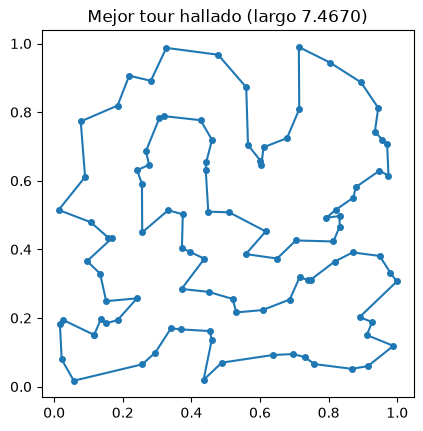

In [16]:
# Mejor tour global encontrado por cualquier variante
mejor_t = min((r for rs, _ in resultados.values() for r in rs), key=lambda r: r["mejor"])
tt = mejor_t["tour"][np.r_[0:100, 0]]
fig, ax = plt.subplots(figsize=(4.8, 4.8))
ax.plot(P100[tt, 0], P100[tt, 1], "o-", ms=4); ax.set_aspect("equal"); ax.grid(False)
ax.set_title(f"Mejor tour hallado (largo {mejor_t['mejor']:.4f})"); plt.show()

**Cómo leer la tabla.** Compara medias y desviaciones, no solo mínimos. Si la diferencia entre dos variantes es menor que
una desviación estándar, con 8 semillas no es una conclusión firme. En esta ejecución (semillas fijas, reproducible): las variantes con **Path Relinking por aristas**
obtienen las menores brechas medias, junto con GRASP reactivo y GRASP con memoria, que mejoran claramente a GRASP con $\alpha$ fijo;
Path Relinking por posiciones (Hamming) no mejora a GRASP básico, de acuerdo con el análisis del camino. El reactivo
concentra su probabilidad en los $\alpha$ pequeños en esta instancia (gráfico de la sección 10), lo que explica que supere a los
dos $\alpha$ fijos probados. El número de **iteraciones GRASP** muestra el costo oculto
de Path Relinking: cada iteración cuesta más (camino + búsqueda local del intermedio), así que con el mismo presupuesto hace
menos construcciones. La ventaja de PR, si aparece, es que cada iteración extra **aprovecha la información** del pool.
En la sección 5 ($n=50$) el 2-opt con muchos reinicios casi siempre llega al mismo mejor tour y las diferencias son mínimas; con
$n=100$ las diferencias se acentúan (ejercicio 4 propone aumentar aún más $n$ y variar el presupuesto).

## Ventajas y limitaciones

| Aspecto | GRASP | GRASP con memoria / reactivo | Path Relinking |
|---|---|---|---|
| Idea | multi-arranque con construcción aleatorizada + LS | aprende $\alpha$ o sesga hacia aristas élite | explora el camino entre élites |
| Ventajas | pocos parámetros ($\alpha$, N); trivial de paralelizar; iteraciones independientes | menos calibración manual; intensifica | convierte memoria en búsqueda dirigida; hibrida bien con LS |
| Limitaciones | sin memoria: puede repetir óptimos locales | memoria sesga y puede reducir diversidad; $\delta$ y $\gamma$ nuevos | requiere distancia y movimiento acordes al problema; costo por iteración mayor |

## Resumen
- **GRASP** = construcción golosa aleatorizada (RCL) + búsqueda local, repetido; $\alpha$ controla el compromiso calidad-diversidad.
- La RCL por **valor** adapta su tamaño a la dispersión de costos; por **cardinalidad** es fija.
- **GRASP reactivo** aprende $\alpha$ con probabilidades $\propto(F^*/A_i)^\delta$; **con memoria** sesga la construcción con frecuencias de aristas élite.
- Las **distancias** entre permutaciones miden cosas distintas; para TSP la distancia de aristas es la que respeta la estructura.
- **Path Relinking** recorre el camino entre dos soluciones élite (forward/backward/mixto) y refina el mejor intermedio con búsqueda local; el **pool élite** debe mantener diversidad.
- Se compara siempre con presupuesto igual, varias semillas y media $\pm$ desviación.

## Ejercicios propuestos
1. Implementa Path Relinking para el QAP con la distancia de Hamming (intercambios) y compara contra la versión por posiciones del TSP.
2. Añade *truncated* PR: detener el camino tras recorrer una fracción $\beta$ de la distancia inicial; estudia $\beta$.
3. Reemplaza el sorteo de la guía proporcional a la distancia por una guía siempre óptima del pool. ¿Cambia la diversidad del pool?
4. Repite la comparación con $n=100$ y tres presupuestos. ¿Cuándo supera Path Relinking a GRASP con más iteraciones?
5. Implementa el *evolutionary path relinking* (aplicar PR entre todas las parejas del pool tras la búsqueda) y mide su costo.
6. Combina GRASP con la lista de candidatos de [búsqueda tabú](06-busqueda-tabu.ipynb) en la construcción y en la LS.

## Referencias
- Feo, T. A. & Resende, M. G. C. (1989). *A probabilistic heuristic for a computationally difficult set covering problem*. Operations Research Letters, 8.
- Feo, T. A. & Resende, M. G. C. (1995). *Greedy randomized adaptive search procedures*. Journal of Global Optimization, 6.
- Prais, M. & Ribeiro, C. C. (2000). *Reactive GRASP: An application to a matrix decomposition problem in TDMA traffic assignment*. INFORMS Journal on Computing, 12(3).
- Fleurent, C. & Glover, F. (1999). *Improved constructive multistart strategies for the quadratic assignment problem using adaptive memory*. INFORMS Journal on Computing, 11(2).
- Glover, F. (1997). *Tabu search and adaptive memory programming – advances, applications and challenges*. En Interfaces in Computer Science and Operations Research.
- Glover, F., Laguna, M. & Martí, R. (2000). *Fundamentals of scatter search and path relinking*. Control and Cybernetics, 29(3).
- Laguna, M. & Martí, R. (1999). *GRASP and path relinking for 2-layer straight line crossing minimization*. INFORMS Journal on Computing, 11(1).
- Resende, M. G. C. & Ribeiro, C. C. (2010). *Greedy randomized adaptive search procedures: advances, hybridizations, and applications*. En Handbook of Metaheuristics (2.ª ed.), Springer.